# Customer Spending Analysis

In this project I look at 2,240 customers of a retail company and try to understand **what makes some customers spend much more than others**.

Questions I wanted to answer:
1. How much do customers spend, and on what products?
2. Does income, age, education or family situation change how much people spend?
3. Are these differences real or just chance? (statistical tests)
4. Can we predict how much a customer will spend?

**Tools:** Python (pandas, NumPy, matplotlib, seaborn, SciPy, scikit-learn)

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# chart style used in the whole notebook
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.color': '#ecebe7',
    'axes.axisbelow': True,
})

In [2]:
df = pd.read_csv('campaignData.csv')
print(df.shape)
df.head()

(2240, 13)


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
0,1957,Graduation,Single,58138.0,0,0,58,635,88,546,172,88,88
1,1954,Graduation,Single,46344.0,1,1,38,11,1,6,2,1,6
2,1965,Graduation,Together,71613.0,0,0,26,426,49,127,111,21,42
3,1984,Graduation,Together,26646.0,1,0,26,11,4,20,10,3,5
4,1981,PhD,Married,58293.0,1,0,94,173,43,118,46,27,15


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year_Birth        2240 non-null   int64  
 1   Education         2240 non-null   str    
 2   Marital_Status    2240 non-null   str    
 3   Income            2216 non-null   float64
 4   Kidhome           2240 non-null   int64  
 5   Teenhome          2240 non-null   int64  
 6   Recency           2240 non-null   int64  
 7   MntWines          2240 non-null   int64  
 8   MntFruits         2240 non-null   int64  
 9   MntMeatProducts   2240 non-null   int64  
 10  MntFishProducts   2240 non-null   int64  
 11  MntSweetProducts  2240 non-null   int64  
 12  MntGoldProds      2240 non-null   int64  
dtypes: float64(1), int64(10), str(2)
memory usage: 227.6 KB


In [4]:
df.describe().round(1)

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
count,2240.0,2216.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0
mean,1968.8,52247.3,0.4,0.5,49.1,303.9,26.3,167.0,37.5,27.1,44.0
std,12.0,25173.1,0.5,0.5,29.0,336.6,39.8,225.7,54.6,41.3,52.2
min,1893.0,1730.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,1959.0,35303.0,0.0,0.0,24.0,23.8,1.0,16.0,3.0,1.0,9.0
50%,1970.0,51381.5,0.0,0.0,49.0,173.5,8.0,67.0,12.0,8.0,24.0
75%,1977.0,68522.0,1.0,1.0,74.0,504.2,33.0,232.0,50.0,33.0,56.0
max,1996.0,666666.0,2.0,2.0,99.0,1493.0,199.0,1725.0,259.0,263.0,362.0


## 2. Data cleaning

Things I found while checking the data:
- **Income** has 24 missing values.
- **Year_Birth** has 1893, 1899 and 1900. Those customers would be over 110 years old, so these are entry errors.
- One customer has an income of **666,666**, far above everyone else (next highest is about 162,000).
- **Marital_Status** has odd values like "YOLO" and "Absurd".

In [5]:
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
print('Lowest birth years:', sorted(df['Year_Birth'])[:5])
print('Highest incomes:', sorted(df['Income'].dropna(), reverse=True)[:3])
print()
print(df['Marital_Status'].value_counts())

Missing values:
Income    24
dtype: int64

Lowest birth years: [1893, 1899, 1900, 1940, 1941]
Highest incomes: [666666.0, 162397.0, 160803.0]

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [6]:
rows_before = len(df)

# birth years before 1920 are not realistic
df = df[df['Year_Birth'] >= 1920]

# remove the one extreme income
df = df[~(df['Income'] > 200000)]

# only 24 rows (about 1%) have no income, so I drop them instead of guessing
df = df.dropna(subset=['Income'])

# 'Alone' means the same as 'Single'; 'YOLO' and 'Absurd' are not real answers
df['Marital_Status'] = df['Marital_Status'].replace({'Alone': 'Single'})
df = df[~df['Marital_Status'].isin(['YOLO', 'Absurd'])]

df = df.reset_index(drop=True)
print('Rows before:', rows_before)
print('Rows after :', len(df))
print('Removed    :', rows_before - len(df))

Rows before: 2240
Rows after : 2208
Removed    : 32


## 3. New columns (feature engineering)

- **Age**: the data comes from around 2014 (the original dataset covers customers who joined in 2012-2014), so I use 2014 as the reference year. Using today's year would make everyone about 12 years older than they were when they were shopping.
- **TotalSpent**: sum of all the `Mnt` columns (spending in dollars on each product type).
- **LivesAlone**: 0 if Married or Together, otherwise 1.
- **Children**: Kidhome + Teenhome.
- **FamilySize**: 1 or 2 adults (from LivesAlone) + children.
- **IsParent**: 1 if the customer has at least one child.
- **EducationLevel**: `Basic` and `Graduation` (bachelor's level) are Undergraduate; `2n Cycle`, `Master` and `PhD` are Postgraduate.

In [7]:
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

df['Age'] = 2014 - df['Year_Birth']
df['TotalSpent'] = df[spend_cols].sum(axis=1)
df['LivesAlone'] = np.where(df['Marital_Status'].isin(['Married', 'Together']), 0, 1)
df['Children'] = df['Kidhome'] + df['Teenhome']
df['FamilySize'] = np.where(df['LivesAlone'] == 1, 1, 2) + df['Children']
df['IsParent'] = np.where(df['Children'] > 0, 1, 0)
df['EducationLevel'] = np.where(df['Education'].isin(['Basic', 'Graduation']),
                                'Undergraduate', 'Postgraduate')

new_cols = ['Age', 'TotalSpent', 'LivesAlone', 'Children', 'FamilySize', 'IsParent', 'EducationLevel']
df[new_cols].head()

,Age,TotalSpent,LivesAlone,Children,FamilySize,IsParent,EducationLevel
0,57,1617,1,0,1,0,Undergraduate
1,60,27,1,2,3,1,Undergraduate
2,49,776,0,0,2,0,Undergraduate
3,30,53,0,1,3,1,Undergraduate
4,33,422,0,1,3,1,Postgraduate


In [8]:
df[new_cols].describe(include='all').round(2)

,Age,TotalSpent,LivesAlone,Children,FamilySize,IsParent,EducationLevel
count,2208.0,2208.00,2208.00,2208.00,2208.00,2208.00,2208
unique,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,Undergraduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,1168
mean,45.1,606.90,0.35,0.95,2.60,0.71,NaN
std,11.7,602.78,0.48,0.75,0.91,0.45,NaN
min,18.0,5.00,0.00,0.00,1.00,0.00,NaN
25%,37.0,69.00,0.00,0.00,2.00,0.00,NaN
50%,44.0,396.00,0.00,1.00,3.00,1.00,NaN
75%,55.0,1047.25,1.00,1.00,3.00,1.00,NaN


What the numbers say:
- Average age is about 45 (range 18 to 74).
- Average spending is about \$607, but the median is only about \$396. The mean is much higher than the median, so a smaller group of big spenders pulls the average up.
- About 71% of customers are parents (IsParent mean 0.71), and around 35% live alone.
- Education is split fairly evenly: about 53% Undergraduate and 47% Postgraduate.

## 4. Exploratory analysis

### 4.1 How much do customers spend?

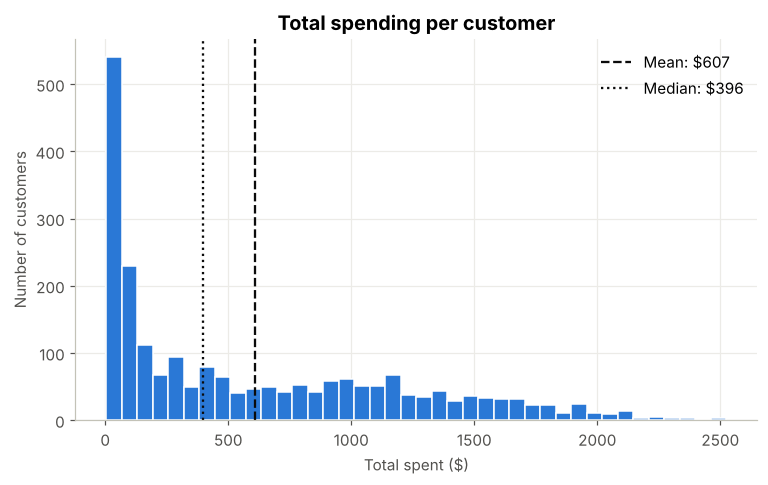

In [9]:
fig, ax = plt.subplots()
ax.hist(df['TotalSpent'], bins=40, color=BLUE, edgecolor='white')
ax.axvline(df['TotalSpent'].mean(), color='#0b0b0b', linestyle='--', linewidth=1.5,
           label=f"Mean: ${df['TotalSpent'].mean():.0f}")
ax.axvline(df['TotalSpent'].median(), color='#0b0b0b', linestyle=':', linewidth=1.5,
           label=f"Median: ${df['TotalSpent'].median():.0f}")
ax.legend(frameon=False)
ax.set_title('Total spending per customer')
ax.set_xlabel('Total spent ($)')
ax.set_ylabel('Number of customers')
plt.show()

Spending is **right-skewed**: most customers spend a little and a long tail spends a lot. Because of this I also use a non-parametric test later, not only the t-test.

### 4.2 What do they spend on?

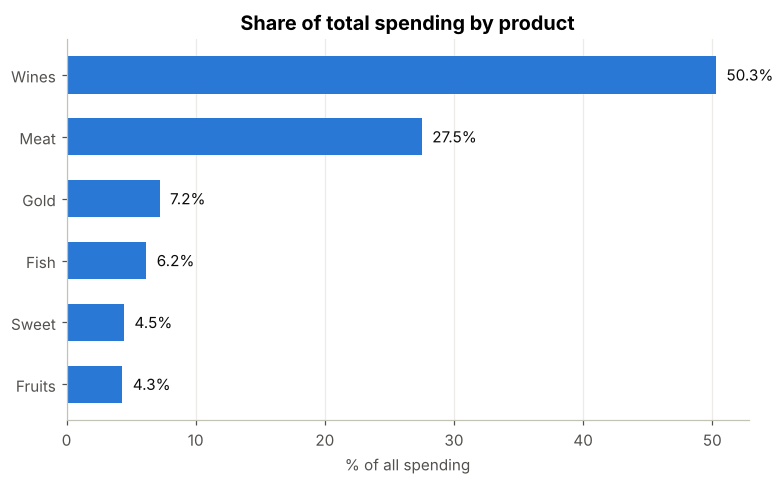

In [10]:
product_share = (df[spend_cols].sum() / df[spend_cols].sum().sum() * 100).sort_values()
labels = [c.replace('Mnt', '').replace('Products', '').replace('Prods', '') for c in product_share.index]

fig, ax = plt.subplots()
ax.barh(labels, product_share.values, color=BLUE, height=0.6)
for i, v in enumerate(product_share.values):
    ax.text(v + 0.8, i, f'{v:.1f}%', va='center', color='#0b0b0b')
ax.set_title('Share of total spending by product')
ax.set_xlabel('% of all spending')
ax.grid(axis='y', visible=False)
plt.show()

**Wine and meat make up almost 78% of all spending.** Fruits and sweets are under 5% each.

### 4.3 Income and spending

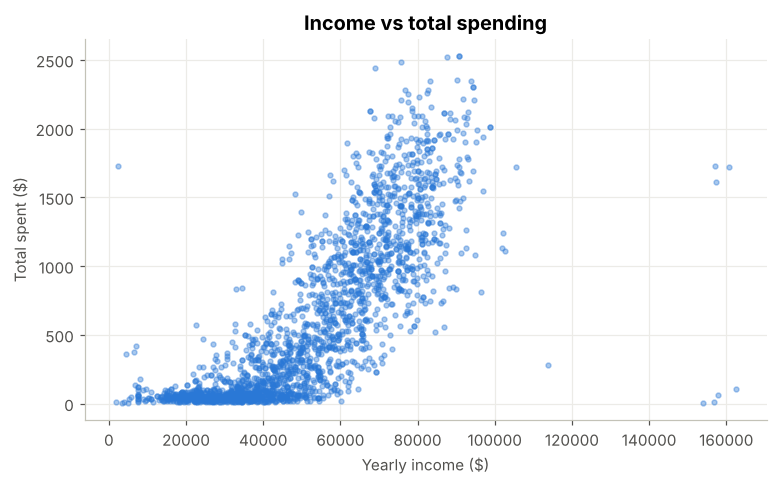

In [11]:
fig, ax = plt.subplots()
ax.scatter(df['Income'], df['TotalSpent'], s=10, alpha=0.4, color=BLUE)
ax.set_title('Income vs total spending')
ax.set_xlabel('Yearly income ($)')
ax.set_ylabel('Total spent ($)')
plt.show()

There is a clear upward pattern: **customers with higher income spend more.** I test how strong this is in section 5.

### 4.4 Children and spending

            mean  count
Children               
0         1104.0    630
1          476.0   1112
2          247.0    416
3          256.0     50


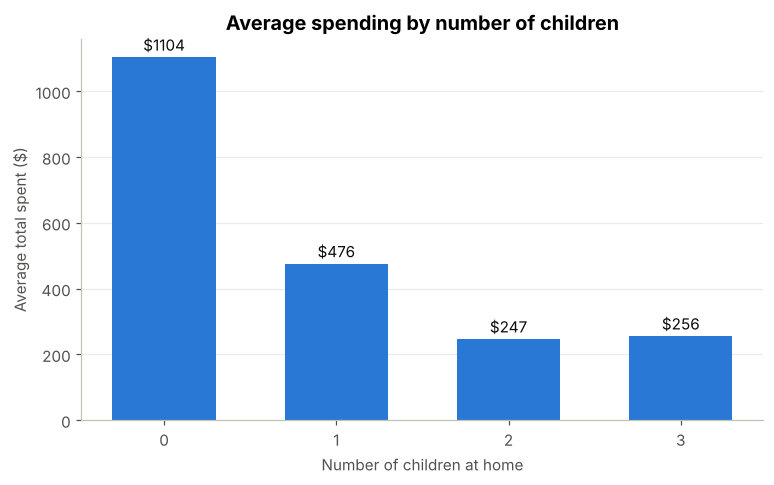

In [12]:
by_children = df.groupby('Children')['TotalSpent'].agg(['mean', 'count']).round(0)
print(by_children)

fig, ax = plt.subplots()
ax.bar(by_children.index.astype(str), by_children['mean'], color=BLUE, width=0.6)
for x, v in zip(by_children.index.astype(str), by_children['mean']):
    ax.text(x, v + 20, f'${v:.0f}', ha='center', color='#0b0b0b')
ax.set_title('Average spending by number of children')
ax.set_xlabel('Number of children at home')
ax.set_ylabel('Average total spent ($)')
ax.grid(axis='x', visible=False)
plt.show()

This is the biggest difference I found. **Customers with no children spend about \$1,104 on average, more than double those with one child (\$476)**, and about four times those with two or three.

### 4.5 Age, education and living situation

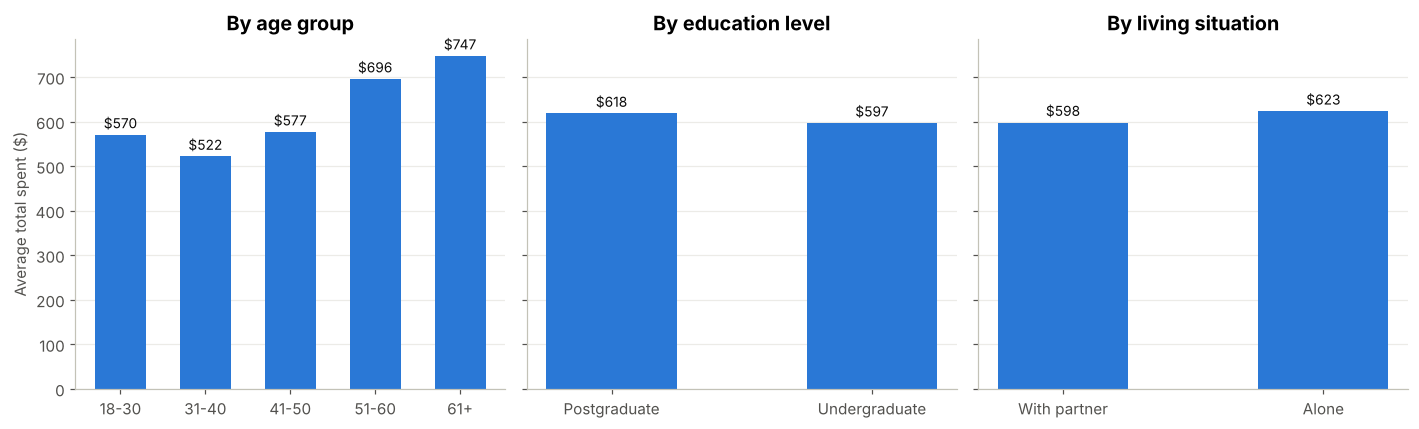

In [13]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 30, 40, 50, 60, 80],
                        labels=['18-30', '31-40', '41-50', '51-60', '61+'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

age_avg = df.groupby('AgeGroup', observed=True)['TotalSpent'].mean()
axes[0].bar(age_avg.index.astype(str), age_avg.values, color=BLUE, width=0.6)
axes[0].set_title('By age group')
axes[0].set_ylabel('Average total spent ($)')

edu_avg = df.groupby('EducationLevel')['TotalSpent'].mean()
axes[1].bar(edu_avg.index, edu_avg.values, color=BLUE, width=0.5)
axes[1].set_title('By education level')

alone_avg = df.groupby('LivesAlone')['TotalSpent'].mean()
axes[2].bar(['With partner', 'Alone'], alone_avg.values, color=BLUE, width=0.5)
axes[2].set_title('By living situation')

for ax in axes:
    ax.grid(axis='x', visible=False)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 15, f'${p.get_height():.0f}',
                ha='center', color='#0b0b0b', fontsize=9)
plt.tight_layout()
plt.show()

- Older customers spend somewhat more (61+ spend about \$747 vs about \$522 for 31-40).
- Education level and living alone show **almost no difference** in spending.

### 4.6 Correlation between numeric columns

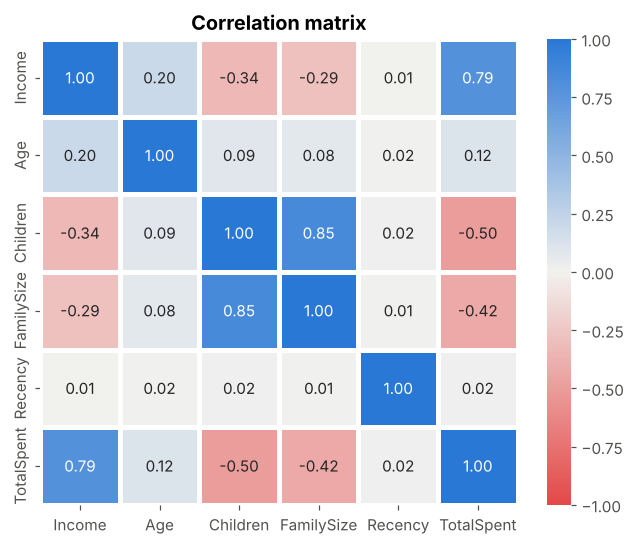

In [14]:
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list('div', ['#e34948', '#f2f1ee', '#2a78d6'])

num_cols = ['Income', 'Age', 'Children', 'FamilySize', 'Recency', 'TotalSpent']
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=diverging, vmin=-1, vmax=1,
            linewidths=2, linecolor='white', ax=ax)
ax.set_title('Correlation matrix')
plt.show()

- **Income and TotalSpent: +0.79** (strong positive).
- **Children and TotalSpent: -0.50** (moderate negative).
- Age (+0.12) and Recency (+0.02) are hardly related to spending.
- Children and FamilySize are highly correlated (0.85), which makes sense because FamilySize is built from Children. I keep this in mind for the model.

## 5. Statistical tests

The charts show differences, but I want to check if they are **statistically significant** or could be random. I use a significance level of **0.05**.

### Test 1: Is income related to spending? (correlation test)
- H0: there is no correlation between income and total spending.
- H1: there is a correlation.

In [15]:
r, p = stats.pearsonr(df['Income'], df['TotalSpent'])
rho, p_s = stats.spearmanr(df['Income'], df['TotalSpent'])
print(f'Pearson r  = {r:.3f}, p-value = {p:.2e}')
print(f'Spearman rho = {rho:.3f}, p-value = {p_s:.2e}')

Pearson r  = 0.793, p-value = 0.00e+00
Spearman rho = 0.853, p-value = 0.00e+00


p-value is far below 0.05, so **I reject H0. Income and spending are strongly and positively related.** Spearman (0.85) is even higher than Pearson, which means the relationship is consistently increasing even if it is not a perfect straight line.

### Test 2: Do parents and non-parents spend differently? (t-test)
- H0: average spending is the same for parents and non-parents.
- H1: average spending is different.

The two groups have different sizes and variances, so I use **Welch's t-test** (`equal_var=False`). Because spending is skewed, I also run the **Mann-Whitney U test**, which does not assume normal data.

In [16]:
parents = df[df['IsParent'] == 1]['TotalSpent']
non_parents = df[df['IsParent'] == 0]['TotalSpent']

print(f'Non-parents: n = {len(non_parents)}, mean = ${non_parents.mean():.0f}')
print(f'Parents    : n = {len(parents)}, mean = ${parents.mean():.0f}')

t, p_t = stats.ttest_ind(non_parents, parents, equal_var=False)
u, p_u = stats.mannwhitneyu(non_parents, parents)
print(f'Welch t-test  : t = {t:.2f}, p-value = {p_t:.2e}')
print(f'Mann-Whitney U: p-value = {p_u:.2e}')

Non-parents: n = 630, mean = $1104
Parents    : n = 1578, mean = $409
Welch t-test  : t = 24.70, p-value = 7.35e-103
Mann-Whitney U: p-value = 5.03e-105


Both p-values are almost zero, so **I reject H0. Non-parents spend significantly more (about 2.7 times) than parents.**

### Test 3: Is being a parent linked to being a high spender? (chi-square test)
I label a customer as a **high spender** if their TotalSpent is above the median.
- H0: being a parent and being a high spender are independent.
- H1: they are related.

In [17]:
df['HighSpender'] = np.where(df['TotalSpent'] > df['TotalSpent'].median(), 1, 0)

table = pd.crosstab(df['IsParent'], df['HighSpender'])
table.index = ['Not parent', 'Parent']
table.columns = ['Low spender', 'High spender']
print(table)
print()
print((pd.crosstab(df['IsParent'], df['HighSpender'], normalize='index') * 100).round(1))

chi2, p_c, dof, expected = stats.chi2_contingency(table)
print(f'\nChi-square = {chi2:.1f}, dof = {dof}, p-value = {p_c:.2e}')

            Low spender  High spender
Not parent          131           499
Parent              974           604

HighSpender     0     1
IsParent               
0            20.8  79.2
1            61.7  38.3

Chi-square = 300.1, dof = 1, p-value = 3.17e-67


**79% of non-parents are high spenders, compared with only 38% of parents.** The p-value is far below 0.05, so the two are clearly related.

### Test 4: Does education level change spending? (t-test)
- H0: Undergraduate and Postgraduate customers spend the same on average.

In [18]:
post = df[df['EducationLevel'] == 'Postgraduate']['TotalSpent']
under = df[df['EducationLevel'] == 'Undergraduate']['TotalSpent']
print(f'Postgraduate mean = ${post.mean():.0f}, Undergraduate mean = ${under.mean():.0f}')

t_e, p_e = stats.ttest_ind(post, under, equal_var=False)
print(f'Welch t-test: t = {t_e:.2f}, p-value = {p_e:.3f}')

Postgraduate mean = $618, Undergraduate mean = $597
Welch t-test: t = 0.84, p-value = 0.400


p-value is above 0.05, so **I cannot reject H0. Education level does not make a meaningful difference to spending.** This is useful too: a marketing team should not target customers based on education.

## 6. Predicting total spending

I train models to predict TotalSpent from Income and the new columns. I compare:
1. **Linear Regression**
2. **SGD Regressor** (linear model trained with gradient descent, needs scaled data)
3. **Random Forest** (can capture non-linear patterns)

In [19]:
df['EducationEncoded'] = np.where(df['EducationLevel'] == 'Postgraduate', 1, 0)

features = ['Income', 'Age', 'LivesAlone', 'Children', 'FamilySize', 'IsParent', 'EducationEncoded']
X = df[features]
y = df['TotalSpent']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

# scaling for SGD: fit only on the training data so the test data stays unseen
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Train: (1766, 7)  Test: (442, 7)


In [20]:
models = {
    'Linear Regression': (LinearRegression(), X_train, X_test),
    'SGD Regressor': (SGDRegressor(max_iter=5000, tol=1e-4, random_state=42), X_train_s, X_test_s),
    'Random Forest': (RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42), X_train, X_test),
}

results, predictions = [], {}
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    predictions[name] = pred
    results.append({
        'Model': name,
        'R2': r2_score(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
    })

results = pd.DataFrame(results).set_index('Model').round(3)
results

,R2,MAE,RMSE
Model,,,
Linear Regression,0.660,262.403,367.294
SGD Regressor,0.660,261.809,367.292
Random Forest,0.761,212.990,308.148


I use three metrics:
- **R²**: share of the variation in spending that the model explains (closer to 1 is better).
- **MAE**: average size of the error in dollars, easy to explain to non-technical people.
- **RMSE**: like MAE but punishes big errors more.

I don't use the plain sum of errors because positive and negative errors cancel out, and the sum of squared errors just grows with the number of rows. MSE/RMSE divide by the number of rows, so they can be compared across datasets.

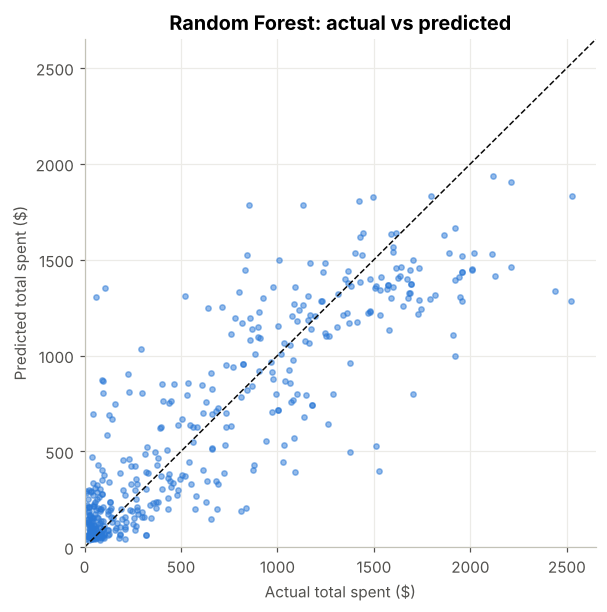

,Actual,Predicted,Error
0,433,364.0,69.0
1,1156,1187.0,-31.0
2,2524,1284.0,1240.0
3,192,149.0,43.0
4,728,532.0,196.0
5,37,45.0,-8.0
6,654,145.0,509.0
7,2119,1935.0,184.0
8,47,114.0,-67.0
9,61,79.0,-18.0


In [21]:
best = results['R2'].idxmax()
best_pred = predictions[best]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_pred, s=12, alpha=0.5, color=BLUE)
lim = [0, max(y_test.max(), best_pred.max()) * 1.05]
ax.plot(lim, lim, color='#0b0b0b', linestyle='--', linewidth=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title(f'{best}: actual vs predicted')
ax.set_xlabel('Actual total spent ($)')
ax.set_ylabel('Predicted total spent ($)')
plt.show()

errors = pd.DataFrame({'Actual': y_test.values, 'Predicted': best_pred.round(0)})
errors['Error'] = errors['Actual'] - errors['Predicted']
errors.head(10)

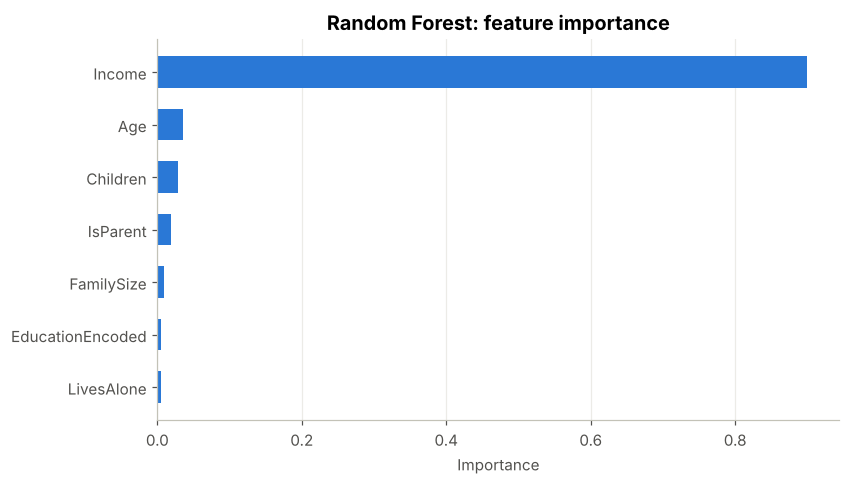

In [22]:
rf = models['Random Forest'][0]
importance = pd.Series(rf.feature_importances_, index=features).sort_values()

fig, ax = plt.subplots()
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_title('Random Forest: feature importance')
ax.set_xlabel('Importance')
ax.grid(axis='y', visible=False)
plt.show()

**Model results**
- Linear Regression and SGD give almost the same result (R² about 0.66). That is expected: both are linear models, SGD just finds the coefficients with gradient descent instead of a formula.
- **Random Forest is the best model: R² 0.76 and an average error (MAE) of about \$213**, compared with about \$262 for the linear models. Spending does not grow in a straight line with income, and the forest can follow that curve.
- In the actual vs predicted chart, the model does well for low and medium spenders but **under-predicts some very high spenders**. Income and family alone cannot fully explain the biggest spenders.
- **Income alone accounts for about 90% of the feature importance.** Children and age add a little; education and living alone add almost nothing, which matches the statistical tests.

## 7. Key findings

1. **Income is the strongest driver of spending** (correlation 0.79, p < 0.001).
2. **Customers without children spend about 2.7 times more** than parents (\$1,104 vs \$409). 79% of non-parents are high spenders compared with 38% of parents.
3. **Wine and meat are about 78% of all spending.** Fruits and sweets are small.
4. **Education level and living alone make no real difference** to spending (education t-test p = 0.40).
5. Spending is right-skewed: the median customer spends about \$396, while the mean is about \$607.
6. A Random Forest model predicts spending with **R² 0.76** (average error about \$213), better than linear regression (R² 0.66).

## 8. Recommendations

- **Target high-income customers without children** for premium wine and meat promotions. They are the biggest spenders.
- **For parents, try family-focused offers** (bundles, discounts on everyday products). Their spending is much lower and may be limited by family costs.
- **Do not segment marketing by education level.** It does not change spending.
- Because a few customers bring a large part of the revenue, a **loyalty program for the top spenders** would protect that income.

## 9. Limitations

- The data has no dates of purchase, so I can't see trends over time.
- Age is based on 2014 as the reference year.
- These results show relationships, not cause and effect. For example, parents may spend less because of lower income, not only because of children.